# Experiment 6: Implementation and Investigation of Shor's Algorithm Using Qiskit

**Course:** Quantum Computing and Algorithms  
**Name:** Ritesh Roshan Sahoo  
**Roll Number:** DL.AI.U4AID24036  
**Email:** riteshroshansahoo01@gmail.com

## Aim

To implement and investigate Shor's algorithm using Qiskit for integer factorization, and to study period finding, quantum interference, classical post-processing and the effect of noise on quantum computation.

## Setup

In [1]:
%pip install --quiet qiskit qiskit-aer matplotlib pylatexenc

Note: you may need to restart the kernel to use updated packages.


In [2]:
from math import gcd
from fractions import Fraction

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from qiskit import (
    QuantumCircuit,
    QuantumRegister,
    ClassicalRegister,
    transpile,
)
from qiskit.circuit.library import QFTGate
from qiskit.quantum_info import Operator
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error

simulator = AerSimulator()

## Task 1: Classical Period Finding

### Problem Statement

For $N = 15$ and $a = 7$, calculate $a^x \bmod N$ for $x = 0, 1, \ldots, 7$ and determine the smallest positive integer $r$ with $a^r \bmod N = 1$. Verify that $7^r \bmod 15 = 1$.

### Program

In [3]:
N = 15
a = 7

print("N =", N)
print("a =", a)
print("gcd(a, N) =", gcd(a, N))

if gcd(a, N) != 1:
    raise ValueError("Choose a coprime base.")

print("\nModular exponentiation sequence:")
for x in range(8):
    value = pow(a, x, N)
    print(f"x = {x}, a^x mod N = {value}")

# Find the order classically
r = 1
while pow(a, r, N) != 1:
    r += 1
print("\nPeriod r =", r)
print("Verification: 7^r mod 15 =", pow(a, r, N))

N = 15
a = 7
gcd(a, N) = 1

Modular exponentiation sequence:
x = 0, a^x mod N = 1
x = 1, a^x mod N = 7
x = 2, a^x mod N = 4
x = 3, a^x mod N = 13
x = 4, a^x mod N = 1
x = 5, a^x mod N = 7
x = 6, a^x mod N = 4
x = 7, a^x mod N = 13

Period r = 4
Verification: 7^r mod 15 = 1


### Observation

| x | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| $7^x \bmod 15$ | 1 | 7 | 4 | 13 | 1 | 7 | 4 | 13 |
*Modular exponentiation table for a = 7, N = 15*

The sequence repeats as $1, 7, 4, 13$, so the **period is $r = 4$** and $7^4 \bmod 15 = 1$ confirms it. Because $r$ is even and $7^2 = 4 \neq -1 \pmod{15}$, the factors follow from $\gcd(7^2 \pm 1, 15) = 3, 5$.

## Task 2: Construction of Modular Multiplication Gates

### Problem Statement

For $N = 15$ construct the reversible operator $U_b|x\rangle = |b x \bmod 15\rangle$ for $0 \le x < 15$, leaving the unused basis state $|15\rangle$ unchanged. Verify the modular powers $7^1, 7^2, 7^4 \bmod 15$ and explain why the operator must be reversible.

### Program

In [4]:
def modular_multiplication_gate(b, N=15):
    n_target = (N - 1).bit_length()
    dim = 2**n_target

    if gcd(b, N) != 1:
        raise ValueError("b and N must be coprime.")

    U = np.zeros((dim, dim), dtype=complex)

    for x in range(dim):
        if x < N:
            y = (b * x) % N
        else:
            y = x
        U[y, x] = 1

    return Operator(U).to_instruction()

U7 = modular_multiplication_gate(7, 15)
U4 = modular_multiplication_gate(4, 15)

print("Multiplication gate for b = 7 constructed.")
print("Multiplication gate for b = 4 constructed.")

print("7^1 mod 15 =", pow(7, 1, 15))
print("7^2 mod 15 =", pow(7, 2, 15))
print("7^4 mod 15 =", pow(7, 4, 15))

Multiplication gate for b = 7 constructed.
Multiplication gate for b = 4 constructed.
7^1 mod 15 = 7
7^2 mod 15 = 4
7^4 mod 15 = 1


In [5]:
# Check that U7 is a permutation matrix and therefore reversible
U = Operator(U7).data.real
print("Non-zero entries per row:   ", U.sum(axis=1).astype(int))
print("Non-zero entries per column:", U.sum(axis=0).astype(int))
print("Unitary (U U^dagger = I):", np.allclose(U @ U.T, np.eye(16)))
print("U7 maps |1> to |", int(np.argmax(U[:, 1])), ">")
print("U7 maps |7> to |", int(np.argmax(U[:, 7])), ">")

Non-zero entries per row:    [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
Non-zero entries per column: [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
Unitary (U U^dagger = I): True
U7 maps |1> to | 7 >
U7 maps |7> to | 4 >


### Observation

Each multiplication operator is a **permutation matrix** with exactly one non-zero entry per row and per column, and $U U^\dagger = I$ holds. $U_7$ sends $|1\rangle$ to $|7\rangle$ and $|7\rangle$ to $|4\rangle$, matching $7^1 = 7$ and $7^2 = 4 \bmod 15$. **The operator must be reversible** because every quantum gate is unitary: multiplication by $b$ coprime to $N$ is a bijection on $\{0, \ldots, 14\}$, so no information is lost and the inverse (multiplication by $b^{-1}$) exists. A non-invertible map could not be a gate.

## Task 3: Quantum Circuit Construction and Simulation

### Problem Statement

Construct and simulate a period-finding circuit for $N = 15$, $a = 7$ with a 4-qubit control register in superposition, a target register initialised to $|1\rangle$, controlled modular multiplication gates $U_{a^{2^k}}$, the inverse QFT and measurement of the control register. Record the circuit, the counts and the histogram, and explain the two registers and the inverse QFT.

### Program

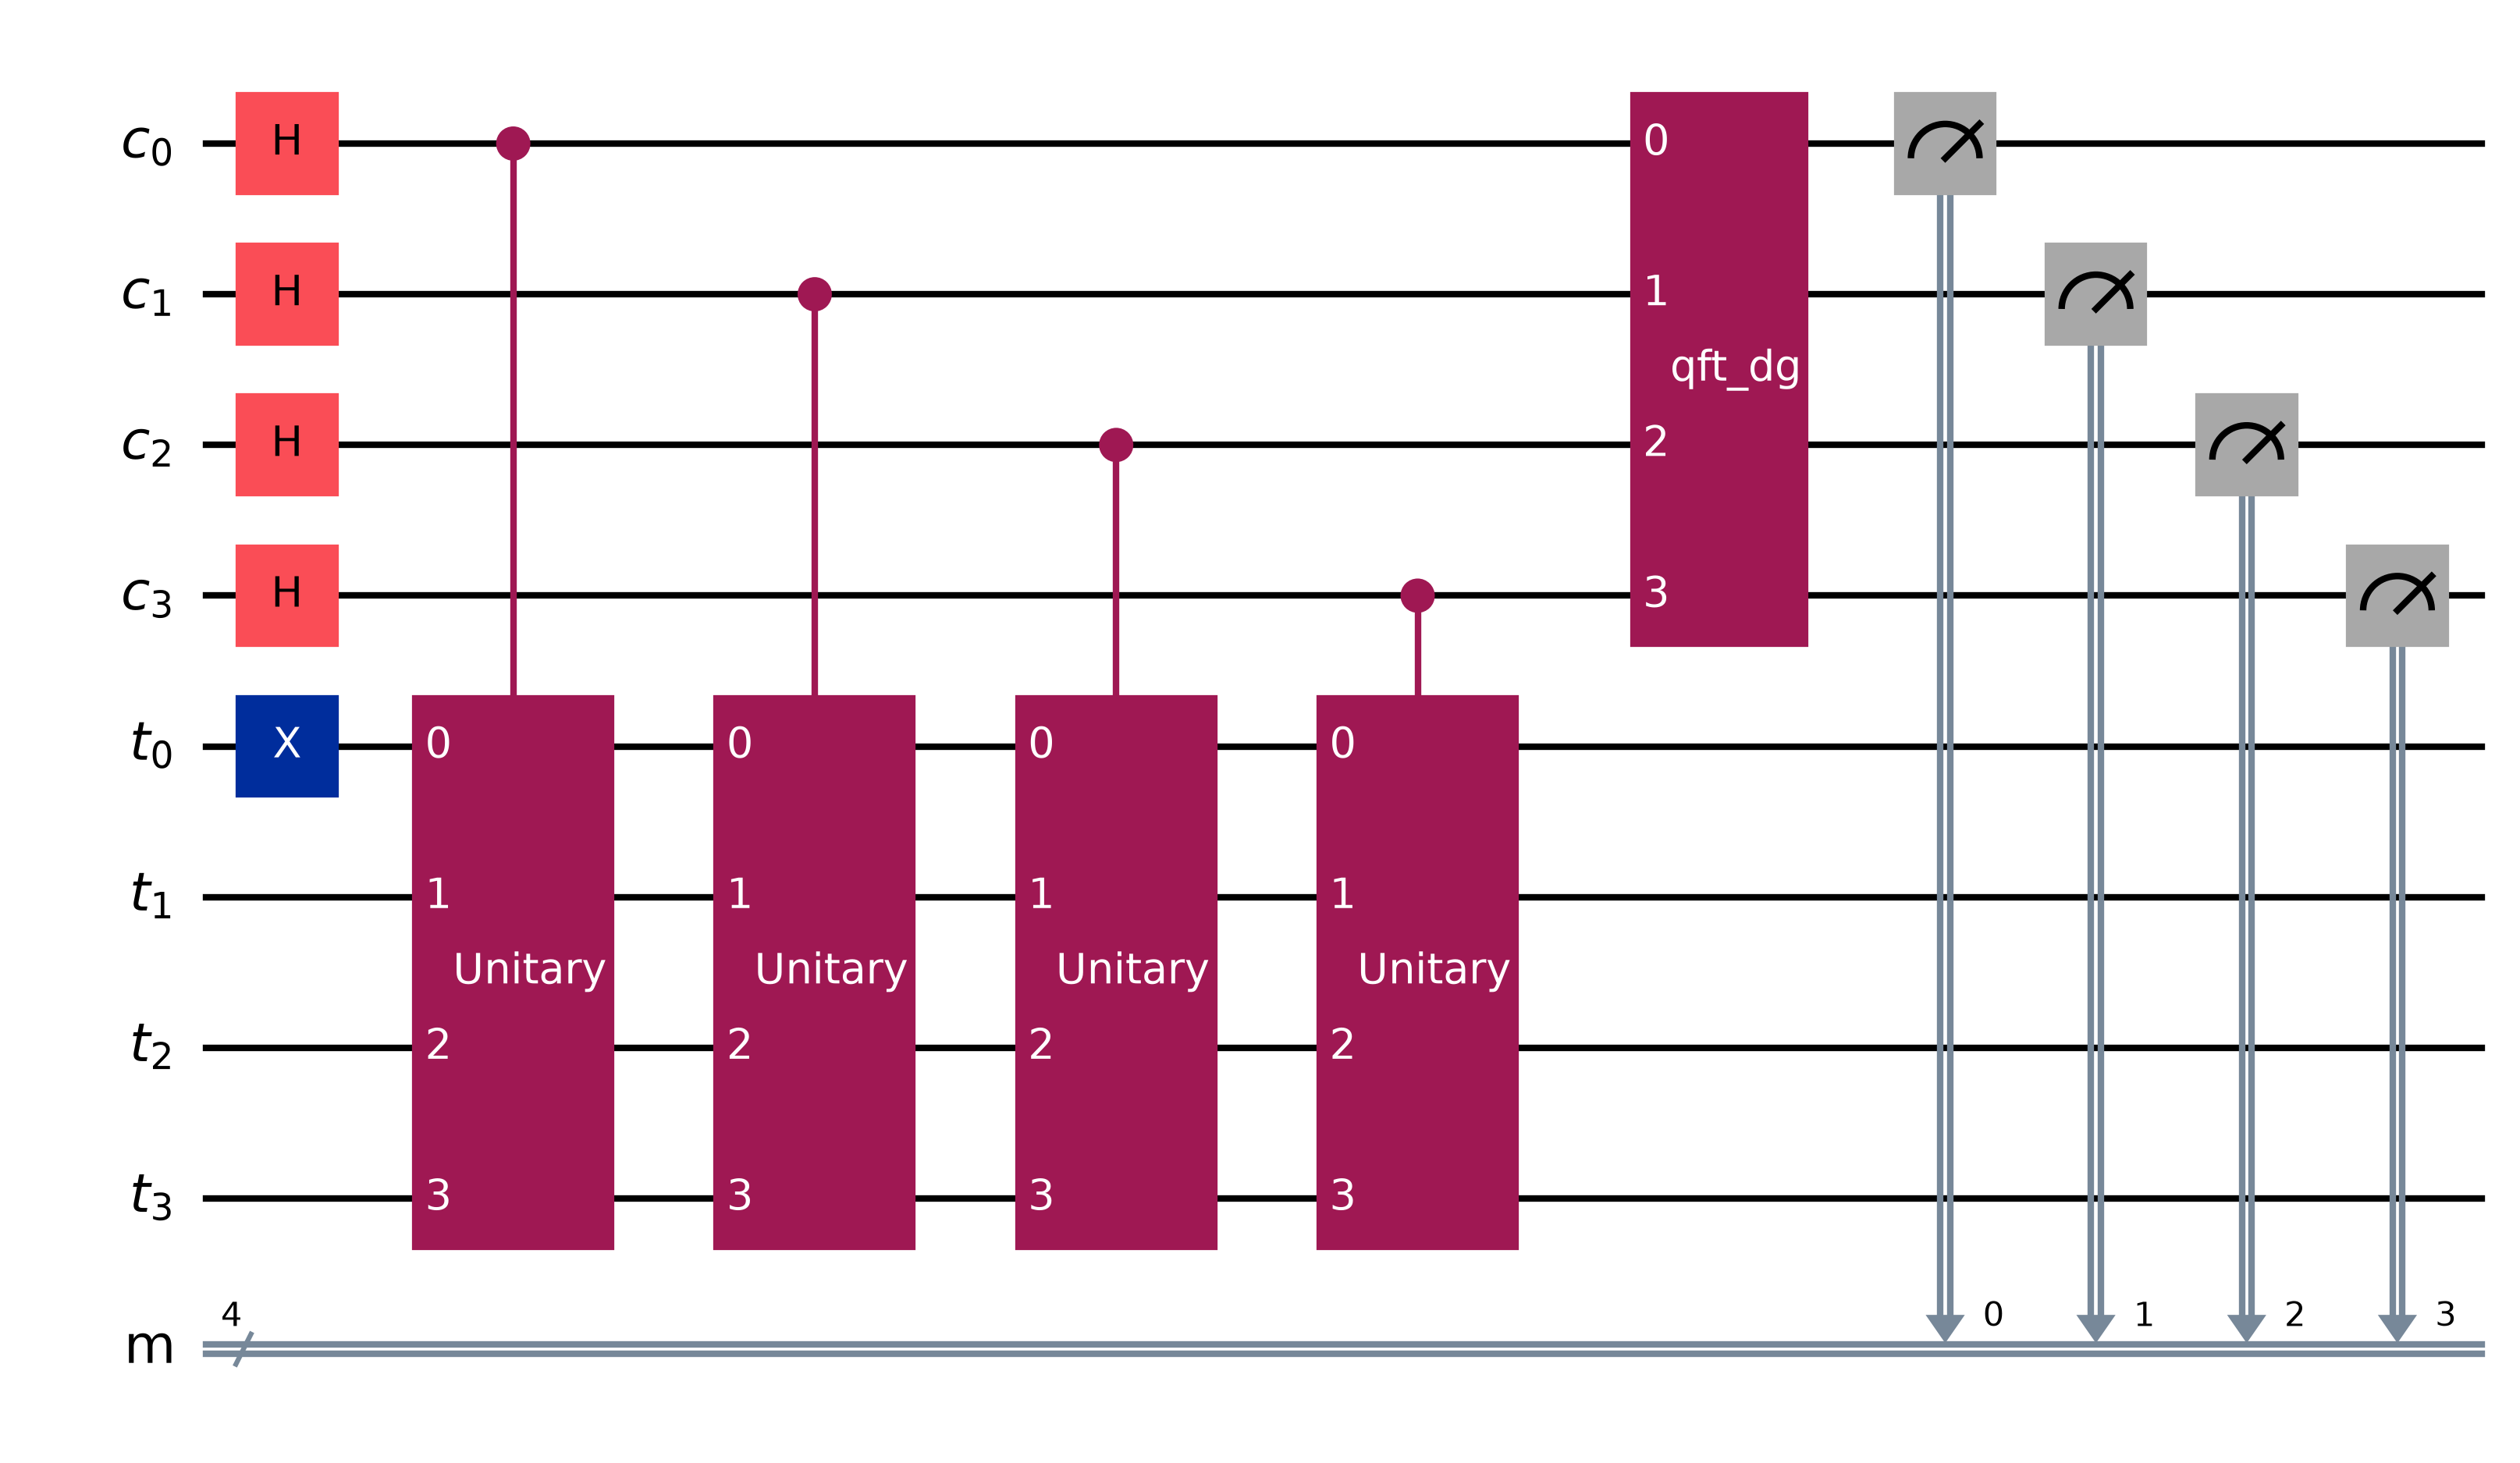


Measurement results:
{'0100': 255, '1100': 256, '0000': 250, '1000': 263}
m =  0 (0000): 250 shots, phase = 0/16 = 0
m =  4 (0100): 255 shots, phase = 4/16 = 1/4
m =  8 (1000): 263 shots, phase = 8/16 = 1/2
m = 12 (1100): 256 shots, phase = 12/16 = 3/4


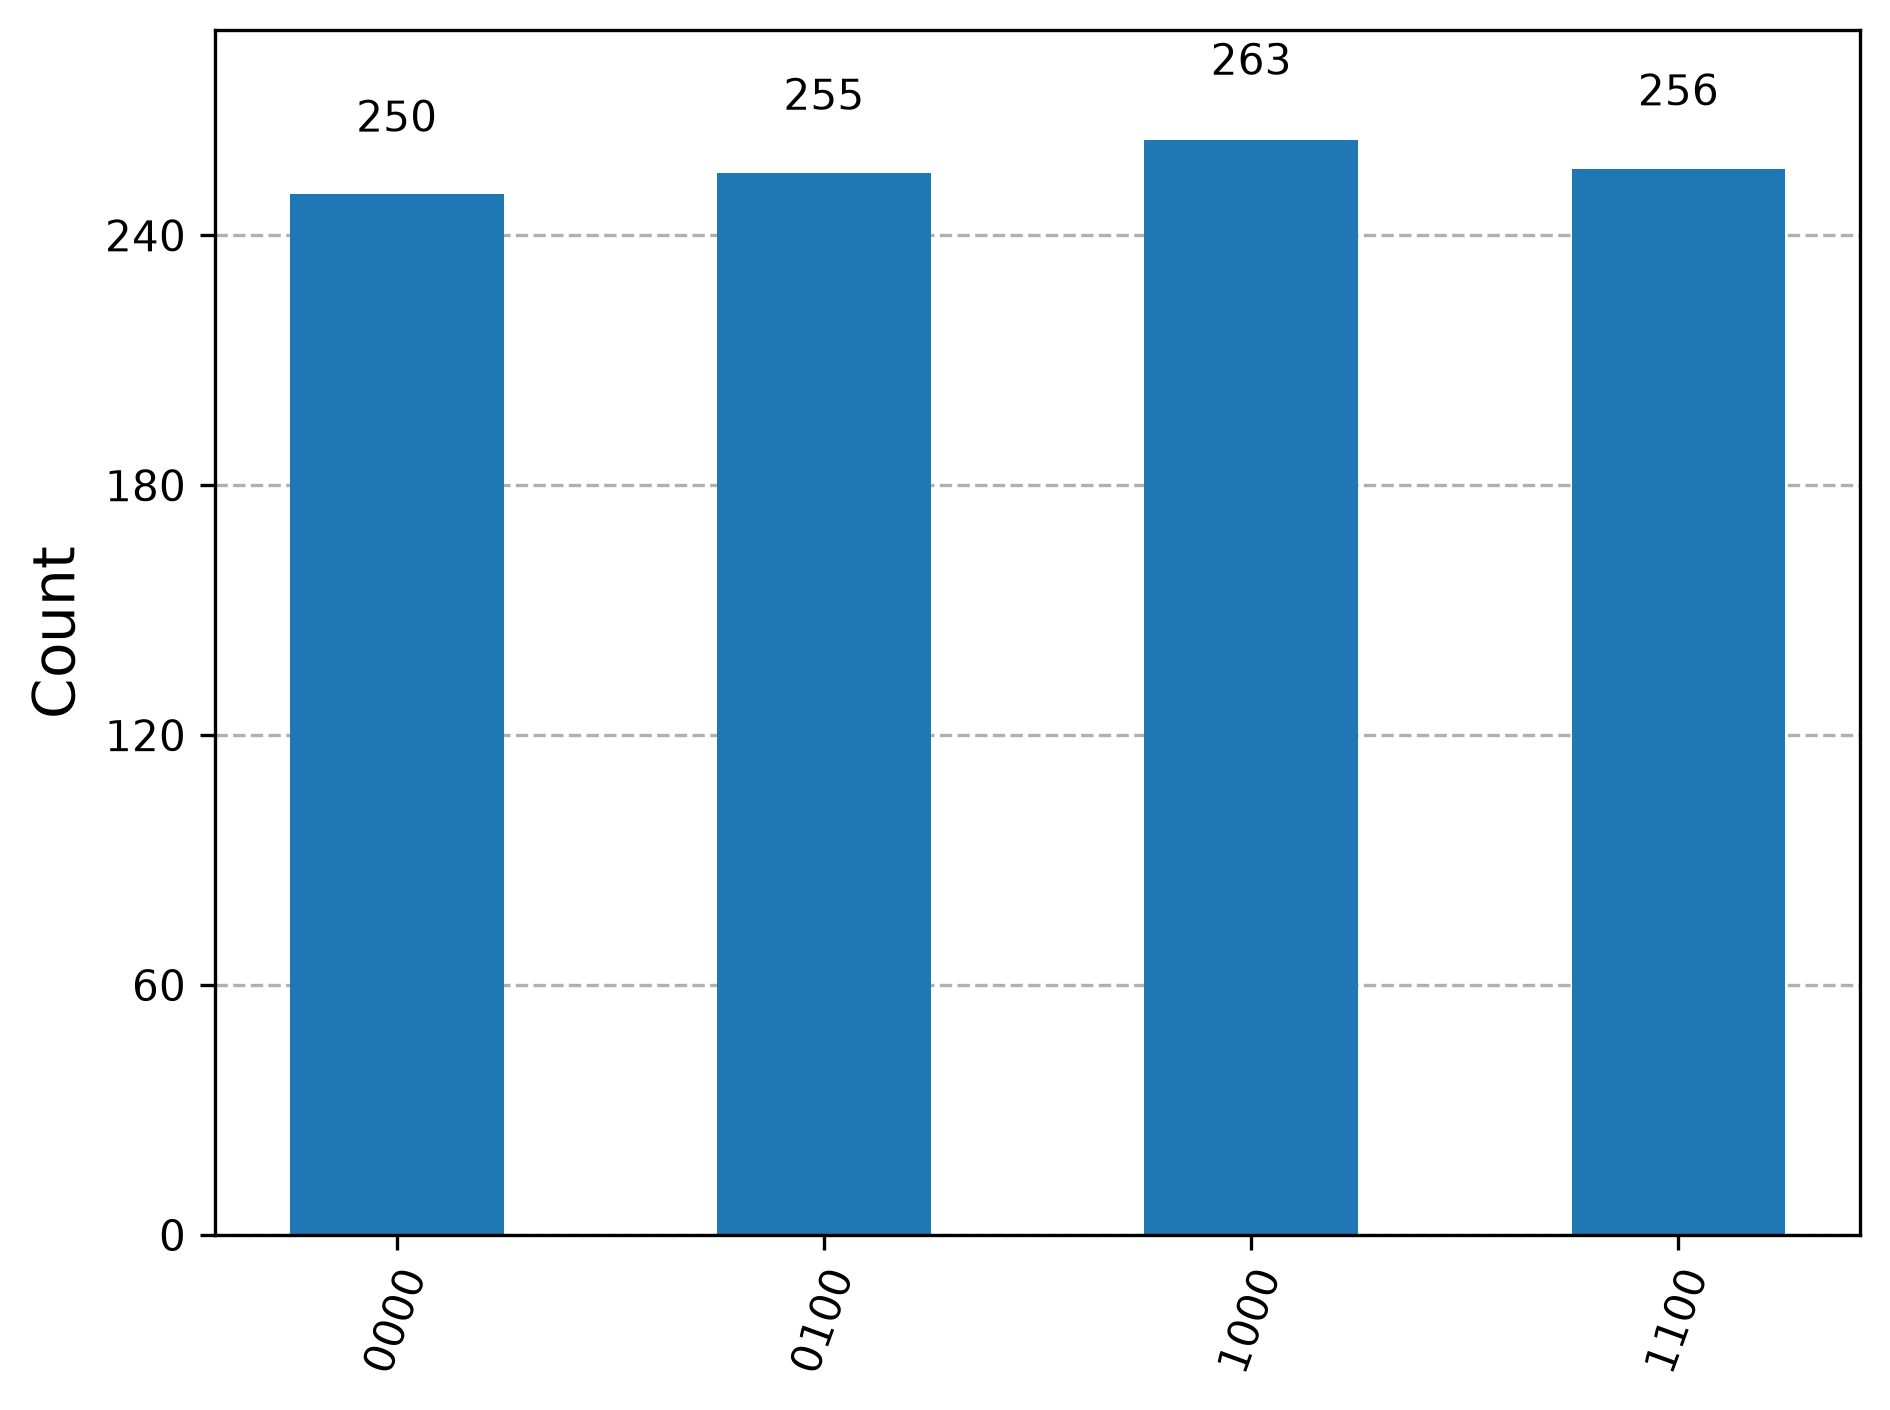

In [6]:
N = 15
a = 7
n_control = 4
n_target = (N - 1).bit_length()

def build_shor_circuit(N, a, n_control=4):
    n_target = (N - 1).bit_length()

    control = QuantumRegister(n_control, "c")
    target = QuantumRegister(n_target, "t")
    measured = ClassicalRegister(n_control, "m")

    qc = QuantumCircuit(control, target, measured)

    # Prepare target register in |1>
    qc.x(target[0])

    # Prepare control register in superposition
    qc.h(control)

    # Controlled modular exponentiation
    for k in range(n_control):
        b = pow(a, 2**k, N)
        gate = modular_multiplication_gate(b, N)
        controlled_gate = gate.control()
        qc.append(controlled_gate, [control[k], *target])

    # Inverse QFT
    qc.append(QFTGate(n_control).inverse(), list(control))

    # Measure control register
    qc.measure(control, measured)

    return qc

qc = build_shor_circuit(N, a, n_control)
display(qc.draw("mpl"))

compiled = transpile(qc, simulator)
result = simulator.run(compiled, shots=1024).result()
counts = result.get_counts()

print("\nMeasurement results:")
print(counts)
for bitstring in sorted(counts):
    m = int(bitstring, 2)
    print(f"m = {m:>2} ({bitstring}): {counts[bitstring]} shots,",
          f"phase = {m}/16 = {Fraction(m, 16)}")
display(plot_histogram(counts))

### Observation

The measurement outcomes concentrate on **$m = 0, 4, 8, 12$**, each with about a quarter of the shots. These are the 4-bit representations of the phases $0, 1/4, 1/2, 3/4$, whose denominators point to the period $r = 4$.

- **Control register**: holds the superposition of all exponents $x$; after the controlled multiplications it is entangled with the value $a^x \bmod N$ in the target register, so it carries the periodicity.
- **Target register**: starts in $|1\rangle$ and accumulates $a^x \bmod N$ through the controlled gates $U_{a^{2^k}}$, one for each control qubit $k$.
- **Inverse QFT**: converts the periodic pattern in the control register into peaks at multiples of $2^{n}/r$, which is what the measurement reads out as $m$.

## Task 4: Period Estimation and Factor Recovery

### Problem Statement

For each measured integer $m$ estimate the phase $\phi = m / 2^n$, where $n$ is the number of control qubits, use continued fractions to obtain a candidate denominator, test its multiples to find a valid order (the denominator may be only a divisor of the true period) and, once an even period $r$ is found, calculate $p = \gcd(a^{r/2} - 1, N)$ and $q = \gcd(a^{r/2} + 1, N)$ and verify the factorisation.

### Program

In [7]:
def estimate_period(m, n_control, a, N):
    if m == 0:
        return None

    phase = Fraction(m, 2**n_control)
    approximation = phase.limit_denominator(N)
    denominator = approximation.denominator

    # Test multiples because the denominator can
    # be a divisor of the true order.
    for candidate in range(denominator, N + 1, denominator):
        if pow(a, candidate, N) == 1:
            return candidate

    return None

print("Period estimates from measurements:")

periods = []

for bitstring, frequency in counts.items():
    m = int(bitstring, 2)
    r_candidate = estimate_period(m, n_control, a, N)
    print(
        f"Outcome={bitstring}, m={m}, "
        f"phase={Fraction(m, 2**n_control)}, "
        f"frequency={frequency}, "
        f"candidate period={r_candidate}"
    )
    if r_candidate is not None:
        periods.append(r_candidate)

# Try candidate periods and recover factors
factors = set()

for r_candidate in sorted(set(periods)):
    if r_candidate % 2 != 0:
        continue

    x = pow(a, r_candidate // 2, N)

    if x == 1 or x == N - 1:
        continue

    p = gcd(x - 1, N)
    q = gcd(x + 1, N)
    print(f"r = {r_candidate}: a^(r/2) mod N = {x},",
          f"gcd({x} - 1, {N}) = {p}, gcd({x} + 1, {N}) = {q}")

    if 1 < p < N and 1 < q < N:
        factors.add(p)
        factors.add(q)

print("\nNon-trivial factors:", sorted(factors))

if factors:
    p = min(factors)
    q = N // p
    print(f"Factorization: {N} = {p} x {q}")
    print("Verification:", p * q == N)
else:
    print("No factors recovered. Repeat the experiment.")

Period estimates from measurements:
Outcome=0100, m=4, phase=1/4, frequency=255, candidate period=4
Outcome=1100, m=12, phase=3/4, frequency=256, candidate period=4
Outcome=0000, m=0, phase=0, frequency=250, candidate period=None
Outcome=1000, m=8, phase=1/2, frequency=263, candidate period=4
r = 4: a^(r/2) mod N = 4, gcd(4 - 1, 15) = 3, gcd(4 + 1, 15) = 5

Non-trivial factors: [3, 5]
Factorization: 15 = 3 x 5
Verification: True


### Observation

| Outcome m | Phase $m/16$ | Continued fraction | Candidate period |
| --- | --- | --- | --- |
| 0 | 0 | none | none (no information) |
| 4 | 1/4 | 1/4 | 4 |
| 8 | 1/2 | 1/2 | 2, then 4 after testing multiples |
| 12 | 3/4 | 3/4 | 4 |
*Period estimation from the measured phases*

Three of the four outcomes lead to the period $r = 4$; $m = 8$ first suggests the divisor 2, which fails the test $a^2 \bmod 15 = 4 \neq 1$, so its multiple 4 is taken. With $r = 4$, $a^{r/2} = 7^2 \bmod 15 = 4$ and the GCD step gives $\gcd(3, 15) = 3$ and $\gcd(5, 15) = 5$, so **$15 = 3 \times 5$** is recovered and verified. The outcome $m = 0$ carries no information, which is why single measurements cannot be relied on and candidates must be checked.

## Task 5: Classical and Quantum Comparison

### Problem Statement

For $N = 15$ and $a = 7$ compare the classical sequential search for the order with the quantum period-finding simulation: record the modular-power checks on one side and the shots and circuit resources on the other, and discuss oracle calls, circuit resources and computational complexity.

### Program

In [8]:
N = 15
a = 7

# Classical order search
classical_checks = 0
r_classical = 1

while True:
    classical_checks += 1
    if pow(a, r_classical, N) == 1:
        break
    r_classical += 1

print("Classical period:", r_classical)
print("Classical modular-power checks:", classical_checks)

# Quantum simulation query count
# Each circuit execution uses the oracle circuit.
quantum_shots = 1024

print("Quantum circuit shots:", quantum_shots)
print("Quantum circuit uses controlled modular arithmetic.")
print("Transpiled depth:", compiled.depth())
print("Transpiled gate count:", compiled.size())
print("Qubits:", qc.num_qubits)

Classical period: 4
Classical modular-power checks: 4
Quantum circuit shots: 1024
Quantum circuit uses controlled modular arithmetic.
Transpiled depth: 910
Transpiled gate count: 1246
Qubits: 8


### Observation

| Parameter | Classical | Quantum |
| --- | --- | --- |
| Main method | sequential order search | quantum period estimation |
| Period information | direct modular powers | measurement phases $m/2^n$ |
| Post-processing | order verification | continued fractions and GCD |
| Hardware | classical processor | quantum circuit or simulator |
| Observed cost | 4 modular-power checks | 1024 shots of a deep circuit |
*Classical and quantum period finding for N = 15, a = 7*

For $N = 15$ the classical search needs only **4 checks**, far less work than the quantum simulation with its thousands of transpiled gates. **This experiment does not demonstrate a quantum speedup**: the simulator runs on classical hardware and the instance is tiny. The quantum advantage is asymptotic, polynomial in the number of bits of $N$ against super-polynomial for the best classical factoring methods, and only appears for large $N$ on a fault-tolerant machine.

## Task 6: Noise and Scalability Investigation

### Problem Statement

**Part A**: run the Task 3 circuit under depolarizing noise (1 percent on `sx`, 3 percent on `cx`) and compare the counts with the ideal run. **Part B**: vary the number of control qubits over $3, 4, 5, 6$ and record circuit depth, gate count, number of distinct outcomes and whether the period can still be recovered.

### Program

Noisy measurement results:
{'1000': 224, '0000': 257, '1100': 190, '0100': 183, '1001': 20, '0001': 29, '1010': 19, '0101': 12, '0010': 20, '0110': 17, '1101': 18, '1110': 18, '0111': 2, '1011': 6, '1111': 5, '0011': 4}
Shots on m = 0, 4, 8, 12 (ideal): 1024
Shots on m = 0, 4, 8, 12 (noisy): 854


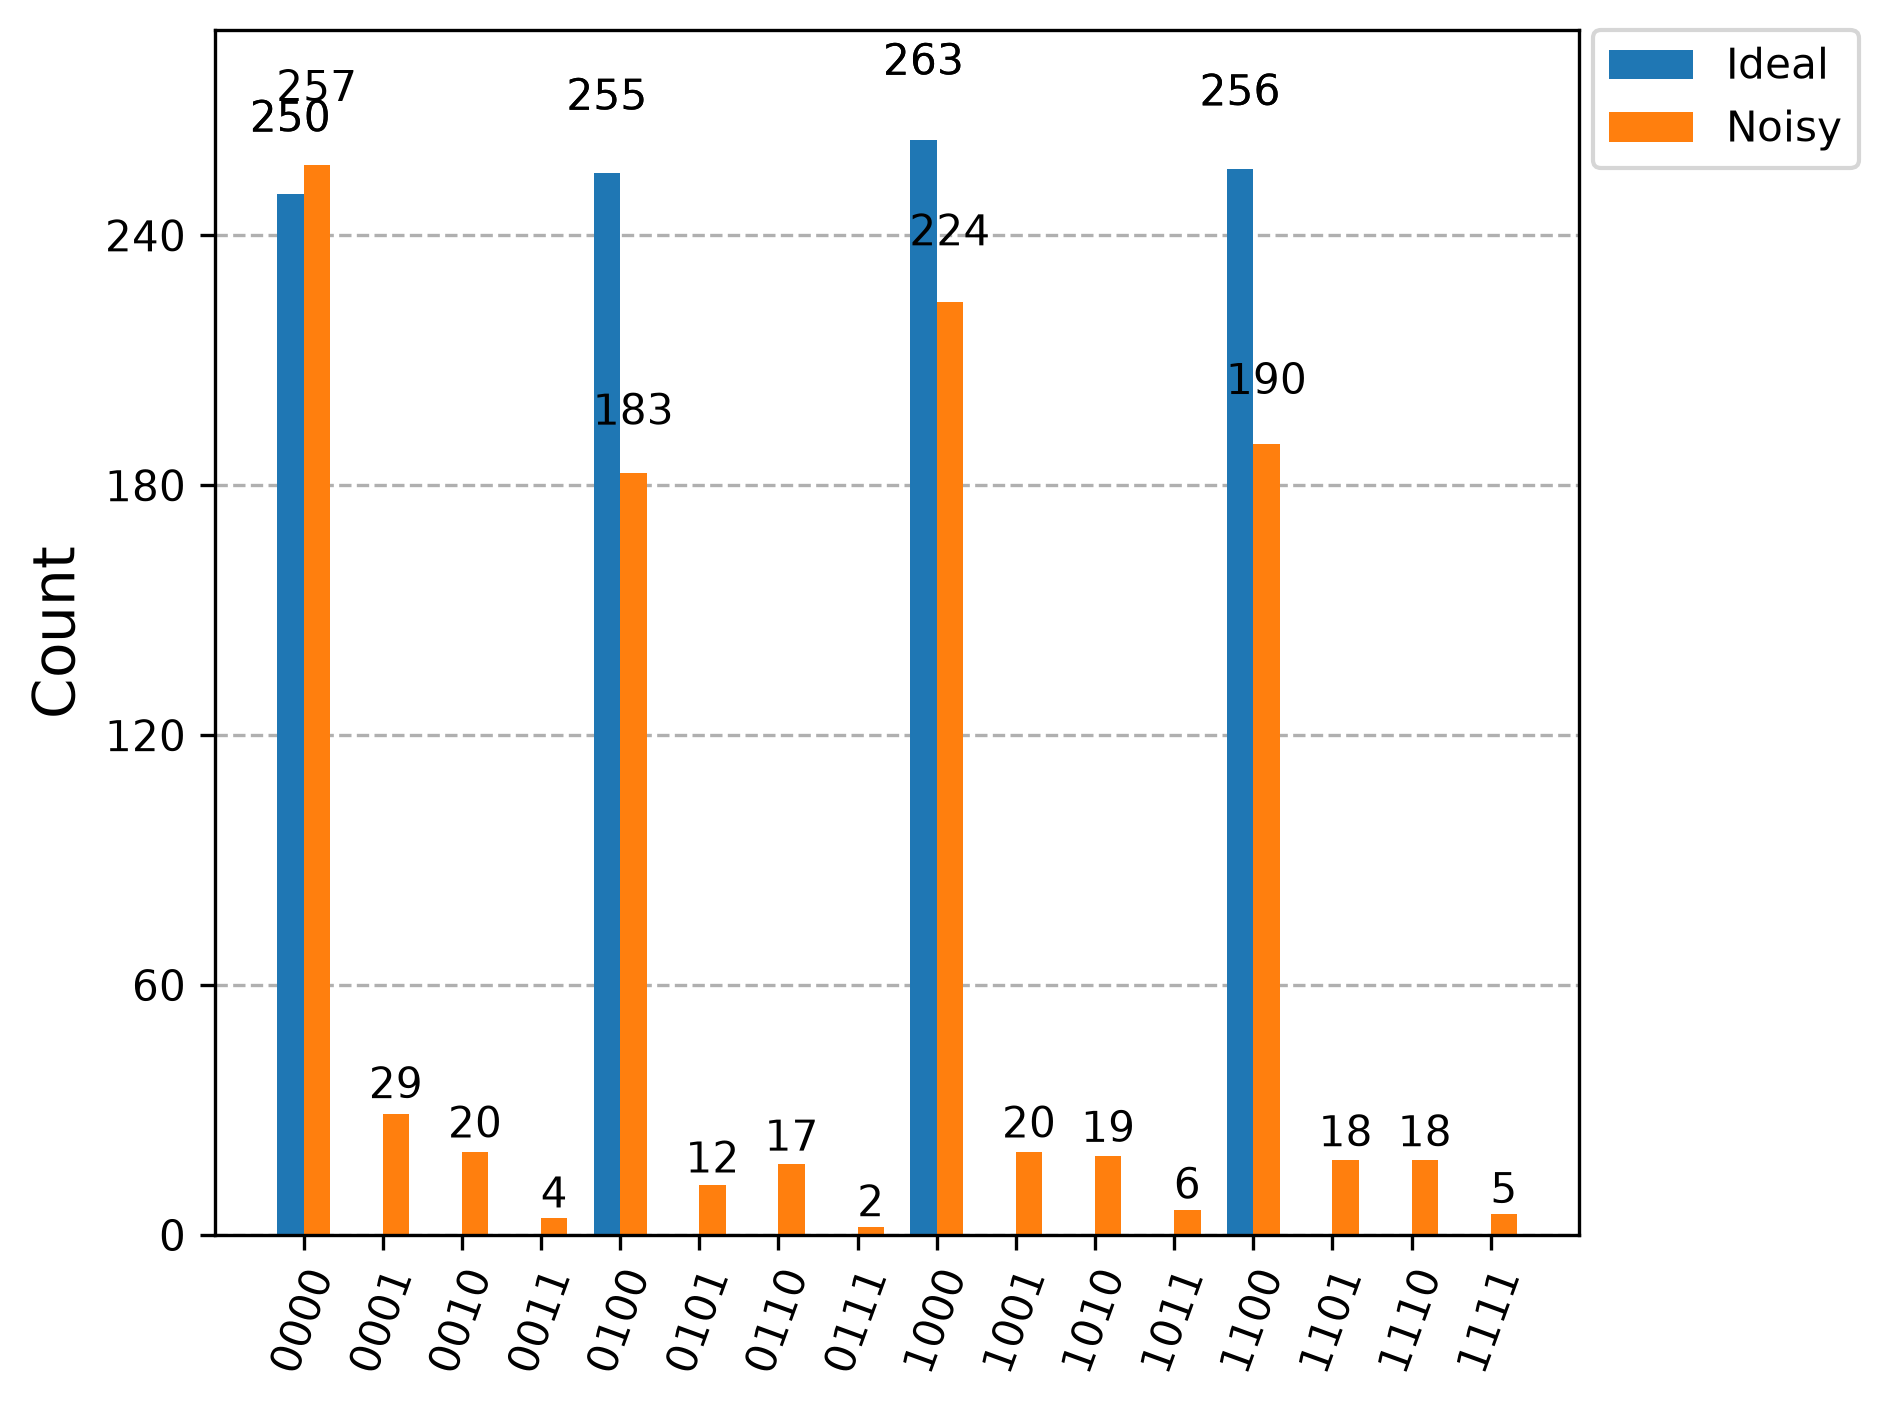

In [9]:
# Part A: noisy simulation of the Task 3 circuit
noise_model = NoiseModel()

error_1q = depolarizing_error(0.01, 1)
error_2q = depolarizing_error(0.03, 2)

# Apply errors to transpiled basis gates
noise_model.add_all_qubit_quantum_error(error_1q, ["sx"])
noise_model.add_all_qubit_quantum_error(error_2q, ["cx"])

noisy_backend = AerSimulator(noise_model=noise_model)

noisy_compiled = transpile(qc, noisy_backend)

noisy_result = noisy_backend.run(
    noisy_compiled, shots=1024
).result()

noisy_counts = noisy_result.get_counts()

print("Noisy measurement results:")
print(noisy_counts)
ideal_peaks = sum(counts.get(k, 0) for k in ["0000", "0100", "1000", "1100"])
noisy_peaks = sum(noisy_counts.get(k, 0) for k in ["0000", "0100", "1000", "1100"])
print("Shots on m = 0, 4, 8, 12 (ideal):", ideal_peaks)
print("Shots on m = 0, 4, 8, 12 (noisy):", noisy_peaks)
display(plot_histogram([counts, noisy_counts], legend=["Ideal", "Noisy"]))

In [10]:
# Part B: vary the number of control qubits
for n_control in [3, 4, 5, 6]:
    test_circuit = build_shor_circuit(N=15, a=7, n_control=n_control)

    compiled_test = transpile(test_circuit, simulator)

    result = simulator.run(compiled_test, shots=1024).result()
    counts_test = result.get_counts()

    periods_found = set()
    for bitstring in counts_test:
        r_found = estimate_period(int(bitstring, 2), n_control, 7, 15)
        if r_found is not None:
            periods_found.add(r_found)

    print("\nControl qubits:", n_control)
    print("Circuit depth:", compiled_test.depth())
    print("Total gates:", compiled_test.size())
    print("Distinct outcomes:", len(counts_test))
    print("Counts:", counts_test)
    print("Period recovered:", 4 in periods_found)


Control qubits: 3
Circuit depth: 910
Total gates: 1240
Distinct outcomes: 4
Counts: {'100': 293, '000': 257, '110': 243, '010': 231}
Period recovered: True



Control qubits: 4
Circuit depth: 910
Total gates: 1246
Distinct outcomes: 4
Counts: {'1100': 252, '0100': 268, '0000': 252, '1000': 252}
Period recovered: True



Control qubits: 5
Circuit depth: 910
Total gates: 1253
Distinct outcomes: 4
Counts: {'11000': 256, '10000': 274, '01000': 256, '00000': 238}
Period recovered: True



Control qubits: 6
Circuit depth: 910
Total gates: 1261
Distinct outcomes: 4
Counts: {'110000': 245, '010000': 265, '000000': 241, '100000': 273}
Period recovered: True


### Observation

**Part A.** Under noise the four ideal peaks $m = 0, 4, 8, 12$ remain the tallest bars, but a sizeable fraction of the shots spreads over the other twelve outcomes. The circuit is deep after transpilation, so even 1 to 3 percent depolarizing error per gate accumulates into a visible background; the period can still be read from the peaks, but a larger noise rate or deeper circuit would bury them.

**Part B.** **More control qubits improve the phase resolution** ($2^n$ bins), so for $r = 4$ the peaks sit exactly on multiples of $2^n/4$ for every size tested, the number of distinct outcomes stays at four and the period is recovered each time. The transpiled depth is the same for all sizes because $7^{2^k} \bmod 15 = 1$ for $k \ge 2$, so the extra controlled multiplications are identities and only the QFT rotations add a few gates; for a general $N$ each extra control qubit would add a full controlled modular multiplication. Classical simulation cost still grows exponentially with the total qubit count, which is why larger instances quickly become impractical to simulate. More shots sharpen the histogram but cannot remove the systematic effect of noise or the uninformative $m = 0$ outcome.

## Conclusion

Shor's algorithm was investigated for N = 15 and a = 7. The classical sequence 1, 7, 4, 13 gave the period 4; reversible modular multiplication gates were built as permutation matrices; the quantum period-finding circuit produced peaks at m = 0, 4, 8 and 12; continued fractions and the GCD step recovered the verified factorisation 15 = 3 x 5. The comparison with the classical search showed that a small simulation demonstrates the mechanism rather than a speedup, and the noise and scaling study showed how depolarizing errors spread the histogram and how resources grow with the control register.